<a href="https://colab.research.google.com/github/fawaztanigbola/Nigeria-ForeCasting-Model/blob/main/Daily_Temperature_Preprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
from google.colab import drive

drive.mount('/content/drive')


Mounted at /content/drive


In [4]:
"/content/drive/MyDrive/Nigeria_Temperature_Project/processed"

'/content/drive/MyDrive/Nigeria_Temperature_Project/processed'

In [5]:
import xarray as xr
ds = xr.open_dataset("/content/drive/MyDrive/Nigeria_Temperature_Project/processed/ERA5_DEM_2015_Jan_Jun.nc")

print(ds)

<xarray.Dataset> Size: 230MB
Dimensions:     (valid_time: 4344, latitude: 101, longitude: 131)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 35kB 2015-01-01 ... 2015-06-30T23...
  * latitude    (latitude) float64 808B 14.0 13.9 13.8 13.7 ... 4.3 4.2 4.1 4.0
  * longitude   (longitude) float64 1kB 2.0 2.1 2.2 2.3 ... 14.7 14.8 14.9 15.0
    number      int64 8B ...
    expver      (valid_time) <U4 70kB ...
Data variables:
    t2m         (valid_time, latitude, longitude) float32 230MB ...
    elevation   (latitude, longitude) float32 53kB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-11-12T15:43 GRIB to CDM+CF via cfgrib-0.9.1...


In [6]:
print(ds['t2m'].attrs.get('units'))

K


In [7]:
not_null = ds['t2m'].count()

In [8]:
print(not_null)

<xarray.DataArray 't2m' ()> Size: 8B
array(53174904)
Coordinates:
    number   int64 8B ...
Attributes: (12/32)
    GRIB_paramId:                             167
    GRIB_dataType:                            fc
    GRIB_numberOfPoints:                      13231
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_stepType:                            instant
    ...                                       ...
    GRIB_totalNumber:                         0
    GRIB_units:                               K
    long_name:                                2 metre temperature
    units:                                    K
    standard_name:                            unknown
    GRIB_surface:                             0.0


In [9]:
total_nans= ds['t2m'].isnull().sum()

In [10]:
print(total_nans,
      total_nans.item())

<xarray.DataArray 't2m' ()> Size: 8B
array(4300560)
Coordinates:
    number   int64 8B ...
Attributes: (12/32)
    GRIB_paramId:                             167
    GRIB_dataType:                            fc
    GRIB_numberOfPoints:                      13231
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_stepType:                            instant
    ...                                       ...
    GRIB_totalNumber:                         0
    GRIB_units:                               K
    long_name:                                2 metre temperature
    units:                                    K
    standard_name:                            unknown
    GRIB_surface:                             0.0 4300560


In [11]:
total_nans= ds['elevation'].isnull().sum()
print(total_nans,
      total_nans.item())

<xarray.DataArray 'elevation' ()> Size: 8B
array(731)
Coordinates:
    number   int64 8B ... 731


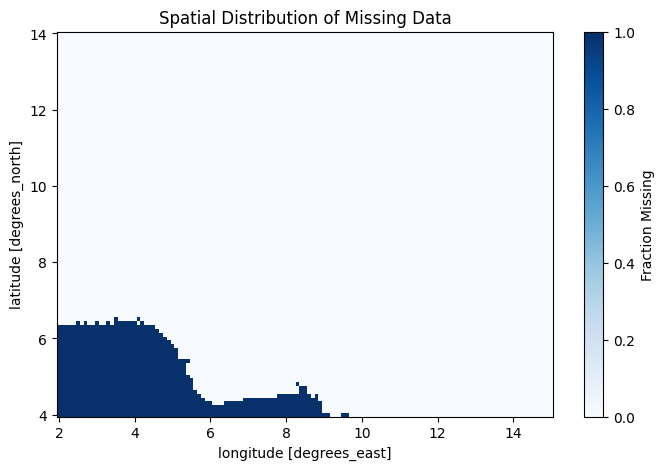

In [12]:
import matplotlib.pyplot as plt
import xarray as xr

# Calculate fraction of missing time steps per spatial pixel
missing_freq = ds['t2m'].isnull().mean(dim='valid_time')

# Plot spatial distribution of missing data
fig, ax = plt.subplots(figsize=(8, 5))
missing_freq.plot(ax=ax, cmap='Blues', cbar_kwargs={'label': 'Fraction Missing'})
ax.set_title('Spatial Distribution of Missing Data')
plt.show()


In [13]:
missing_pct= ds['t2m'].isnull().mean(dim='valid_time')*100
print(missing_pct)

<xarray.DataArray 't2m' (latitude: 101, longitude: 131)> Size: 106kB
array([[  0.,   0.,   0., ...,   0.,   0.,   0.],
       [  0.,   0.,   0., ...,   0.,   0.,   0.],
       [  0.,   0.,   0., ...,   0.,   0.,   0.],
       ...,
       [100., 100., 100., ...,   0.,   0.,   0.],
       [100., 100., 100., ...,   0.,   0.,   0.],
       [100., 100., 100., ...,   0.,   0.,   0.]], shape=(101, 131))
Coordinates:
  * latitude   (latitude) float64 808B 14.0 13.9 13.8 13.7 ... 4.3 4.2 4.1 4.0
  * longitude  (longitude) float64 1kB 2.0 2.1 2.2 2.3 ... 14.7 14.8 14.9 15.0
    number     int64 8B ...
Attributes: (12/32)
    GRIB_paramId:                             167
    GRIB_dataType:                            fc
    GRIB_numberOfPoints:                      13231
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_stepType:                            instant
    ...                                       ...
    GRIB_totalNumber:   

In [14]:
comb_ds = xr.open_mfdataset("/content/drive/MyDrive/Nigeria_Temperature_Project/processed/*.nc",
                               combine="by_coords")

/tmp/ipykernel_2405/2494021891.py:1: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  comb_ds = xr.open_mfdataset("/content/drive/MyDrive/Nigeria_Temperature_Project/processed/*.nc",


In [15]:
print(comb_ds.dims)

FrozenMappingWarningOnValuesAccess({'valid_time': 87673, 'latitude': 101, 'longitude': 131})


In [16]:
print(comb_ds.data_vars)

Data variables:
    t2m        (valid_time, latitude, longitude) float32 5GB dask.array<chunksize=(1, 34, 44), meta=np.ndarray>
    elevation  (valid_time, latitude, longitude) float32 5GB dask.array<chunksize=(1, 101, 131), meta=np.ndarray>


In [17]:
print(comb_ds['valid_time'][0])
print(comb_ds['valid_time'][-1])
print(comb_ds['valid_time'].to_index().is_monotonic_increasing)
print(comb_ds['valid_time'].to_index().is_unique)

<xarray.DataArray 'valid_time' ()> Size: 8B
array('2014-12-31T23:00:00.000000000', dtype='datetime64[ns]')
Coordinates:
    number      int64 8B 0
    valid_time  datetime64[ns] 8B 2014-12-31T23:00:00
    expver      <U4 16B dask.array<chunksize=(), meta=np.ndarray>
Attributes:
    long_name:      time
    standard_name:  time
<xarray.DataArray 'valid_time' ()> Size: 8B
array('2024-12-31T23:00:00.000000000', dtype='datetime64[ns]')
Coordinates:
    number      int64 8B 0
    valid_time  datetime64[ns] 8B 2024-12-31T23:00:00
    expver      <U4 16B dask.array<chunksize=(), meta=np.ndarray>
Attributes:
    long_name:      time
    standard_name:  time
True
True


In [18]:
static_elevation = comb_ds["elevation"].isel(valid_time=0, drop=True)

comb_ds["elevation"] = static_elevation

# Verify dimensions
print("Temperature:", comb_ds["t2m"].dims)
print("Elevation:", comb_ds["elevation"].dims)

Temperature: ('valid_time', 'latitude', 'longitude')
Elevation: ('latitude', 'longitude')


In [19]:
import pandas as pd

comb_ds = comb_ds.assign_coords(
    valid_time=comb_ds.valid_time + pd.Timedelta(hours=1)
)

print(comb_ds.valid_time[0].values)
print(comb_ds.valid_time[-1].values)

2015-01-01T00:00:00.000000000
2025-01-01T00:00:00.000000000


In [20]:
daily_count = comb_ds["t2m"].resample(valid_time="1D").count()

print(daily_count)
print(daily_count.min().values)
print(daily_count.max().values)

<xarray.DataArray 't2m' (valid_time: 3654, latitude: 101, longitude: 131)> Size: 387MB
dask.array<stack, shape=(3654, 101, 131), dtype=int64, chunksize=(1, 34, 44), chunktype=numpy.ndarray>
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 29kB 2015-01-01 ... 2025-01-01
  * latitude    (latitude) float64 808B 14.0 13.9 13.8 13.7 ... 4.3 4.2 4.1 4.0
  * longitude   (longitude) float64 1kB 2.0 2.1 2.2 2.3 ... 14.7 14.8 14.9 15.0
    number      int64 8B 0
Attributes: (12/32)
    GRIB_paramId:                             167
    GRIB_dataType:                            fc
    GRIB_numberOfPoints:                      13231
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_stepType:                            instant
    ...                                       ...
    GRIB_totalNumber:                         0
    GRIB_units:                               K
    long_name:                                2 metre temperat

In [21]:
print("Minimum:", daily_count.min().compute().item())
print("Maximum:", daily_count.max().compute().item())


Minimum: 0


KeyboardInterrupt: 

In [23]:

def process_year(year):

    # 1. Select hourly data for the year
    yearly = comb_ds.sel(
        valid_time=slice(f"{year}-01-01", f"{year}-12-31 23:00")
    )

    # 2. Count valid hourly observations per day
    daily_count = yearly["t2m"].resample(valid_time="1D").count()

    # 3. Calculate daily minimum and maximum
    daily_min = yearly["t2m"].resample(valid_time="1D").min()
    daily_max = yearly["t2m"].resample(valid_time="1D").max()

    # 4. Keep only days with 24 valid observations
    daily_min = daily_min.where(daily_count == 24)
    daily_max = daily_max.where(daily_count == 24)

    # 5. Convert Kelvin to Celsius
    daily_min = daily_min - 273.15
    daily_max = daily_max - 273.15

    # 6. Combine temperatures and static elevation
    daily_ds = xr.Dataset({
        "tmin": daily_min,
        "tmax": daily_max,
        "elevation": comb_ds["elevation"]
    })

    # Save yearly output
    output_path = f"/content/drive/MyDrive/Nigeria_Temperature_Project/processed/daily_temperature_{year}.nc"

    daily_ds.to_netcdf(output_path)

    return output_path


In [24]:
for year in range(2015, 2025):
    process_year(year)

In [22]:
print(comb_ds.values
      )

<bound method Mapping.values of <xarray.Dataset> Size: 5GB
Dimensions:     (valid_time: 87673, latitude: 101, longitude: 131)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 701kB 2015-01-01 ... 2025-01-01
  * latitude    (latitude) float64 808B 14.0 13.9 13.8 13.7 ... 4.3 4.2 4.1 4.0
  * longitude   (longitude) float64 1kB 2.0 2.1 2.2 2.3 ... 14.7 14.8 14.9 15.0
    number      int64 8B 0
    expver      (valid_time) <U4 1MB dask.array<chunksize=(1,), meta=np.ndarray>
Data variables:
    t2m         (valid_time, latitude, longitude) float32 5GB dask.array<chunksize=(1, 34, 44), meta=np.ndarray>
    elevation   (latitude, longitude) float32 53kB dask.array<chunksize=(101, 131), meta=np.ndarray>
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:  